# Crypto Volatility — Machine Learning
Predict unusually high volatility in the next 15 minutes from 60 completed one-minute candles for BTC, ETH and SOL. Outputs are uncalibrated risk scores; no trading action is produced.

Train: April 2025–March 2026. Validation: April–June 2026. Final evaluation: July–September 2026. This is a standalone implementation. The final period has prior analytical exposure and is **not an untouched independent holdout**. Do not tune from its results.

The benchmark is realized volatility of the 59 internal close-to-close returns in 60 candles. The fixed validation quality gate is model macro AP ≥ 1.20 × benchmark macro AP. All three assets receive equal weight.

Run from this folder: `python -m pip install -r requirements.txt`, then `python -m jupyterlab`. Python 3.14 was used for verification.


In [1]:
from pathlib import Path
import os, sys, json, hashlib, time, shutil, subprocess, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve
from sklearn.calibration import calibration_curve
from threadpoolctl import threadpool_limits

# Optional ML_PROJECT_DIR points to this folder; otherwise launch Jupyter here.
ROOT = Path(os.environ.get('ML_PROJECT_DIR', Path.cwd())).expanduser().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if not (ROOT/'data/raw').is_dir():
    raise FileNotFoundError('Launch Jupyter in Machine-Learning or set ML_PROJECT_DIR to it.')
RAW = Path(os.environ.get('ML_RAW_DIR', ROOT/'data/raw')).resolve()
METRICS = ROOT/'results/metrics'; MODEL = ROOT/'results/model'
for folder in [METRICS, MODEL]: folder.mkdir(parents=True, exist_ok=True)
START, TRAIN_END, VALID_END, END = [pd.Timestamp(x,tz='UTC') for x in
    ['2025-04-01','2026-04-01','2026-07-01','2026-10-01']]
SEED = 42
RUN_ID = pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%SZ')
VERSIONS = {p:importlib.metadata.version(p) for p in
    ['numpy','pandas','scikit-learn','matplotlib','joblib','threadpoolctl','nbformat','nbclient']}
print('Project:', ROOT)
print('Python:', platform.python_version())


Project: <repo>
Python: 3.12.16


In [2]:
"""Shared offline/inference calculations. No fitting or future labels in predict_candles."""
from pathlib import Path
import numpy as np
import pandas as pd
import joblib

SYMBOLS = ['BTCUSDT', 'ETHUSDT', 'SOLUSDT']
MINUTE = pd.Timedelta(minutes=1)
NUMERIC = ['open', 'high', 'low', 'close', 'volume', 'trades']
FEATURES = ['return_1', 'return_5', 'return_15', 'return_30', 'rv_5', 'rv_15',
            'rv_30', 'rv_60c_59r', 'range_mean_60', 'volume_ratio_5_60',
            'trades_ratio_5_60', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos']
PREDICTORS = FEATURES + ['symbol']
FEATURE_SPEC = {
    'returns': 'log(C[t]/C[t-k]), k=1,5,15,30',
    'rv': 'sqrt(sum of last k squared log returns), k=5,15,30',
    'benchmark': 'sqrt(sum of 59 internal squared log returns within 60 completed candles)',
    'range_mean_60': 'mean((high-low)/close) over 60 candles',
    'activity_ratios': 'last-5 mean / last-60 mean, base volume and trade count',
    'calendar': 'sine/cosine UTC decision hour and weekday',
    'invalid_policy': 'exclude gaps/nonfinite features/zero ratio denominator; never fill prices',
    'target': 'sqrt(sum of squared log returns t+1 through t+15)); strict > asset training RV90',
}

def utc_open(values, unit='auto'):
    """Convert Binance opening timestamps; historical=us, REST default=ms."""
    s = pd.Series(values).copy()
    if pd.api.types.is_numeric_dtype(s):
        if not np.isfinite(s).all() or not s.mod(1).eq(0).all():
            raise ValueError('Invalid numeric opening timestamp')
        if unit == 'auto':
            median = s.abs().median()
            unit = 'us' if median >= 1e14 else 'ms' if median >= 1e11 else None
        if unit not in ('us', 'ms'):
            raise ValueError('Timestamp unit must be us or ms')
        out = pd.to_datetime(s, unit=unit, utc=True, errors='raise')
    else:
        # Datetime strings without a timezone are ambiguous and must not be assumed local.
        if any(pd.Timestamp(x).tzinfo is None for x in s):
            raise ValueError('Opening timestamps must declare UTC or another timezone')
        out = pd.to_datetime(s, utc=True, errors='raise')
    if out.isna().any() or not out.eq(out.dt.floor('min')).all():
        raise ValueError('Opening times must be complete UTC minute boundaries')
    return out.astype("datetime64[us, UTC]")

def normalize_candles(frame, symbol=None, unit='auto'):
    d = frame.copy().reset_index(drop=True)
    required = ['open_time'] + NUMERIC
    if any(c not in d for c in required):
        raise ValueError('Missing candle columns: ' + str([c for c in required if c not in d]))
    if len(d) == 0:
        raise ValueError('Empty candle input')
    d['open_time'] = utc_open(d.open_time, unit=unit).to_numpy()
    d['open_time'] = pd.to_datetime(d.open_time, utc=True)
    if symbol is not None:
        if 'symbol' in d and not d.symbol.eq(symbol).all():
            raise ValueError('Symbol mismatch')
        d['symbol'] = symbol
    if 'symbol' not in d or d.symbol.nunique() != 1 or d.symbol.iloc[0] not in SYMBOLS:
        raise ValueError('Require one supported symbol')
    if d.open_time.duplicated().any() or not d.open_time.is_monotonic_increasing:
        raise ValueError('Duplicate or unordered opening times')
    for c in NUMERIC:
        d[c] = pd.to_numeric(d[c], errors='raise')
    valid = (np.isfinite(d[NUMERIC]).all(axis=1)
             & d[['open','high','low','close']].gt(0).all(axis=1)
             & d[['volume','trades']].ge(0).all(axis=1)
             & d.trades.mod(1).eq(0)
             & d.low.le(d[['open','close']].min(axis=1))
             & d.high.ge(d[['open','close']].max(axis=1)))
    return d, valid

def past_features(d):
    if d.symbol.nunique() != 1:
        raise ValueError('Features require one asset')
    f = pd.DataFrame(index=d.index)
    logc = np.log(d.close)
    r = logc.diff()
    for k in [1,5,15,30]:
        f[f'return_{k}'] = logc - logc.shift(k)
    for k in [5,15,30]:
        f[f'rv_{k}'] = np.sqrt(r.pow(2).rolling(k, min_periods=k).sum())
    f['rv_60c_59r'] = np.sqrt(r.pow(2).rolling(59, min_periods=59).sum())
    f['range_mean_60'] = ((d.high-d.low)/d.close).rolling(60, min_periods=60).mean()
    for c, name in [('volume','volume_ratio_5_60'),('trades','trades_ratio_5_60')]:
        denom = d[c].rolling(60, min_periods=60).mean().replace(0, np.nan)
        f[name] = d[c].rolling(5, min_periods=5).mean()/denom
    decision = d.open_time + MINUTE
    for label, values, period in [('hour',decision.dt.hour,24),('weekday',decision.dt.day_of_week,7)]:
        f[label+'_sin'] = np.sin(2*np.pi*values/period)
        f[label+'_cos'] = np.cos(2*np.pi*values/period)
    consecutive = d.open_time.diff().eq(MINUTE).rolling(59,min_periods=59).sum().eq(59)
    return f[FEATURES], consecutive & np.isfinite(f[FEATURES]).all(axis=1)

def build_samples(d):
    d = d.reset_index(drop=True)
    f, past_ok = past_features(d)
    r = np.log(d.close).diff()
    future = np.sqrt(r.pow(2).rolling(15,min_periods=15).sum().shift(-15))
    future_ok = (d.open_time.shift(-15)-d.open_time).eq(15*MINUTE) & future.notna()
    f['symbol'] = d.symbol
    f['decision_time'] = d.open_time + MINUTE
    f['label_end_time'] = d.open_time.shift(-15) + MINUTE
    f['future_rv_15'] = future
    return f.loc[past_ok & future_ok].copy(), {
        'candles':len(d), 'invalid_past':int((~past_ok).sum()),
        'invalid_future_after_valid_past':int((past_ok & ~future_ok).sum()),
        'eligible':int((past_ok & future_ok).sum())}

def partition(samples, start, end):
    return samples.loc[samples.decision_time.ge(start) & samples.decision_time.lt(end)
                       & samples.label_end_time.le(end)].copy().reset_index(drop=True)

def predict_candles(candles, bundle_or_path, *, mode='replay', as_of=None,
                    max_age_seconds=None, unit='auto', symbol=None):
    """Score raw candles with a saved pipeline; no training or future labels required.

    Replay requires explicit as_of. Live requires an approved bundle and an explicit freshness limit.
    """
    bundle = joblib.load(bundle_or_path) if isinstance(bundle_or_path,(str,Path)) else bundle_or_path
    d, valid = normalize_candles(candles, symbol=symbol, unit=unit)
    if len(d) != 60 or not valid.all() or not d.open_time.diff().iloc[1:].eq(MINUTE).all():
        raise ValueError('Require exactly 60 consecutive valid candles')
    if mode not in ('live','replay'):
        raise ValueError('mode must be live or replay')
    if mode == 'live' and bundle['metadata']['approval_status'] != 'approved':
        raise ValueError('Candidate is not approved for live use')
    if mode == 'replay' and as_of is None:
        raise ValueError('Replay requires an explicit timezone-aware as_of')
    now = pd.Timestamp.now(tz='UTC') if as_of is None else pd.Timestamp(as_of)
    if now.tzinfo is None:
        raise ValueError('as_of must be timezone aware')
    decision = d.open_time.iloc[-1]+MINUTE
    if now < decision:
        raise ValueError('Last candle is not completed')
    if mode == 'live':
        if max_age_seconds is None or not np.isfinite(max_age_seconds) or max_age_seconds < 0:
            raise ValueError('Live use requires a nonnegative freshness limit')
        if (now-decision).total_seconds() > max_age_seconds:
            raise ValueError('Stale candle window')
    f, eligible = past_features(d)
    if not eligible.iloc[-1]:
        raise ValueError('Invalid feature window')
    row = f.iloc[[-1]].copy()
    row['symbol'] = d.symbol.iloc[0]
    model = bundle['model']
    if list(model.classes_) != [0,1]:
        raise ValueError('Unexpected class mapping')
    score = float(model.predict_proba(row[bundle['metadata']['predictor_order']])[0,1])
    if not np.isfinite(score) or not 0 <= score <= 1:
        raise ValueError('Invalid model score')
    return {'symbol':d.symbol.iloc[0], 'decision_time':decision.isoformat(),
            'last_candle_open':d.open_time.iloc[-1].isoformat(), 'horizon_minutes':15,
            'risk_score':score, 'calibration_status':'uncalibrated', 'mode':mode,
            'model_version':bundle['metadata']['model_version'],
            'approval_status':bundle['metadata']['approval_status'], 'status':'ok',
            'scored_at':pd.Timestamp.now(tz='UTC').isoformat()}


## 1. Load and audit data
Historical opening timestamps use microseconds. REST milliseconds are normalized by the same shared function. Missing or invalid candles are never fabricated; affected sample windows are excluded. Conflicting duplicate opening times stop the run.


In [3]:
COLUMNS = ['open_time','open','high','low','close','volume','close_time','quote_volume',
           'trades','taker_base','taker_quote','unused']
manifest = []; audits = []; assets = {}
for symbol in SYMBOLS:
    pieces = []; invalid_count = 0; duplicates = 0
    for month in pd.period_range('2025-04','2026-09',freq='M'):
        path = RAW/symbol/f'{symbol}-1m-{month}.csv'
        block = pd.read_csv(path,header=None)
        if block.shape[1] != 12: raise ValueError(f'Wrong field count: {path.name}')
        block.columns = COLUMNS
        block = block.apply(pd.to_numeric,errors='raise')
        duplicates += int(block.duplicated().sum())
        block = block.drop_duplicates().sort_values('open_time').reset_index(drop=True)
        d, valid = normalize_candles(block,symbol=symbol,unit='us')
        begin = month.start_time.tz_localize('UTC'); finish = (month+1).start_time.tz_localize('UTC')
        if not (d.open_time.ge(begin) & d.open_time.lt(finish)).all():
            raise ValueError(f'Opening times outside source month: {path.name}')
        extras = ['quote_volume','taker_base','taker_quote']
        valid &= (np.isfinite(block[extras]).all(axis=1) & block[extras].ge(0).all(axis=1)
                  & (block.close_time-block.open_time).eq(59_999_999))
        invalid_count += int((~valid).sum())
        pieces.append(d.loc[valid,['open_time','symbol','open','high','low','close','volume','trades']])
        manifest.append({'file':path.relative_to(RAW).as_posix(),'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
                         'source_rows':len(block),'invalid_rows':int((~valid).sum()),
                         'expected_rows':int((finish-begin)/MINUTE)})
    d = pd.concat(pieces,ignore_index=True).sort_values('open_time').reset_index(drop=True)
    if d.open_time.duplicated().any(): raise ValueError('Duplicate times across monthly files')
    assets[symbol] = d
    audits.append({'symbol':symbol,'valid_candles':len(d),'invalid_candles':invalid_count,
                   'exact_duplicates_removed':duplicates,'missing_minutes':int((END-START)/MINUTE)-len(d),
                   'gap_breaks':int(d.open_time.diff().iloc[1:].ne(MINUTE).sum())})
audit = pd.DataFrame(audits)
display(audit)
audit.to_csv(METRICS/'data_audit.csv',index=False)
(METRICS/'data_manifest.json').write_text(json.dumps(manifest,indent=2))


,symbol,valid_candles,invalid_candles,exact_duplicates_removed,missing_minutes,gap_breaks
0,BTCUSDT,789120,0,0,0,0
1,ETHUSDT,789120,0,0,0,0
2,SOLUSDT,789120,0,0,0,0


11504

## 2. Features, target and chronology
At 10:00 UTC the input comprises openings 09:00–09:59; future returns use the closes of 10:00–10:14 and mature at 10:15. Future RV is the square root of the sum of 15 squared log returns, without annualization. The target is strictly above the asset-specific eligible-training 90th percentile. Preprocessing is fitted on training only.


In [4]:
parts = []; eligibility = []
for symbol,d in assets.items():
    f, counts = build_samples(d)
    parts.append(f); eligibility.append({'symbol':symbol,**counts})
samples = pd.concat(parts,ignore_index=True).sort_values(['decision_time','symbol']).reset_index(drop=True)
train = partition(samples,START,TRAIN_END)
validation = partition(samples,TRAIN_END,VALID_END)
thresholds = train.groupby('symbol').future_rv_15.quantile(.90,interpolation='linear')
for frame in [train,validation]:
    frame['y'] = frame.future_rv_15.gt(frame.symbol.map(thresholds)).astype('int8')
summary = pd.concat([frame.groupby('symbol').agg(rows=('y','size'),event_rate=('y','mean')).assign(partition=name)
                     for name,frame in [('train',train),('validation',validation)]]).reset_index()
display(summary)
summary.to_csv(METRICS/'development_samples.csv',index=False)
pd.DataFrame(eligibility).to_csv(METRICS/'window_eligibility.csv',index=False)


,symbol,rows,event_rate,partition
0,BTCUSDT,525526,0.100001,train
1,ETHUSDT,525526,0.100001,train
2,SOLUSDT,525526,0.100001,train
3,BTCUSDT,131026,0.087364,validation
4,ETHUSDT,131026,0.049395,validation
5,SOLUSDT,131026,0.057340,validation


In [5]:
# Deterministic checks before model fitting.
d = assets['BTCUSDT'].iloc[:220].copy(); t = 150; c = d.close.to_numpy()
features, _ = past_features(d)
built, _ = build_samples(d)
np.testing.assert_allclose(features.loc[t,'return_30'],np.log(c[t]/c[t-30]),rtol=1e-10)
np.testing.assert_allclose(features.loc[t,'rv_60c_59r'],np.sqrt(np.diff(np.log(c[t-59:t+1])) @ np.diff(np.log(c[t-59:t+1]))),rtol=1e-10)
np.testing.assert_allclose(built.loc[t,'future_rv_15'],np.sqrt(np.square(np.log(c[t+1:t+16]/c[t:t+15])).sum()),rtol=1e-10)
request = d.iloc[t-59:t+1].reset_index(drop=True)
request_f, request_ok = past_features(request)
assert request_ok.iloc[-1]
np.testing.assert_allclose(request_f.iloc[-1],features.loc[t],rtol=1e-9,atol=1e-12)
changed = d.copy(); changed.loc[t+1:,'close'] *= np.linspace(1.01,1.03,len(d)-t-1)
altered, _ = past_features(changed)
np.testing.assert_allclose(altered.loc[t],features.loc[t],rtol=1e-12,atol=1e-12)
changed_labels, _ = build_samples(changed)
assert not np.isclose(changed_labels.loc[t,'future_rv_15'],built.loc[t,'future_rv_15'])
gapped = d.drop(index=100).reset_index(drop=True)
_, gap_ok = past_features(gapped)
assert not gap_ok.iloc[100:159].any()
assert 90 not in build_samples(gapped)[0].index
fixture = pd.DataFrame({'decision_time':[TRAIN_END-15*MINUTE,TRAIN_END-14*MINUTE],
                        'label_end_time':[TRAIN_END,TRAIN_END+MINUTE]})
assert len(partition(fixture,START,TRAIN_END)) == 1
assert train.label_end_time.max() <= TRAIN_END
assert validation.label_end_time.max() <= VALID_END
assert not samples[['symbol','decision_time']].duplicated().any()
assert set(thresholds.index) == set(SYMBOLS)
for unit,divisor in [('us',1_000),('ms',1_000_000)]:
    numeric = pd.Series([int(x.value)//divisor for x in request.open_time])
    pd.testing.assert_series_equal(utc_open(numeric,unit=unit),request.open_time,check_names=False)
    pd.testing.assert_series_equal(utc_open(numeric),request.open_time,check_names=False)
try: past_features(pd.concat([assets[s].iloc[:60] for s in SYMBOLS],ignore_index=True))
except ValueError: pass
else: raise AssertionError('Cross-asset features accepted')
print('PASS: UTC us/ms parity, hand calculations, 60-candle parity, future isolation, gaps and split purging.')


PASS: UTC us/ms parity, hand calculations, 60-candle parity, future isolation, gaps and split purging.


## 3. Compare three candidates
Fit one predeclared configuration per family. This is a small validation comparison, not exhaustive tuning. Macro AP is the equal-weight mean of the three asset AP scores; the benchmark uses exactly the same rows. Bootstrap sampling stays inside training, and boosting random early stopping is disabled.


In [6]:
def evaluate(frame,scores,name,bounded=True):
    scores = np.asarray(scores,dtype=float)
    if len(scores) != len(frame) or not np.isfinite(scores).all(): raise ValueError('Invalid scores')
    if bounded and not ((scores>=0)&(scores<=1)).all(): raise ValueError('Scores outside [0,1]')
    rows = []
    for symbol in SYMBOLS:
        mask = frame.symbol.eq(symbol).to_numpy(); y = frame.loc[mask,'y']; p = scores[mask]
        if len(y)==0 or y.nunique()!=2: raise ValueError(f'Non-evaluable asset: {symbol}')
        row = {'model':name,'symbol':symbol,'rows':len(y),'prevalence':float(y.mean()),
               'average_precision':float(average_precision_score(y,p)),
               'roc_auc':float(roc_auc_score(y,p))}
        if bounded: row['brier_score'] = float(brier_score_loss(y,p))
        rows.append(row)
    return pd.DataFrame(rows)

def make_pipeline(classifier,scale=False):
    prep = ColumnTransformer([('numeric',StandardScaler() if scale else 'passthrough',FEATURES),
        ('symbol',OneHotEncoder(handle_unknown='error',sparse_output=False),['symbol'])])
    return Pipeline([('preprocessing',prep),('classifier',classifier)])

benchmark_validation = evaluate(validation,validation.rv_60c_59r,'60-candle RV',False)
benchmark_ap = float(benchmark_validation.average_precision.mean())
required_ap = 1.20*benchmark_ap
candidates = {
    'Logistic Regression':make_pipeline(LogisticRegression(C=1,max_iter=1000,random_state=SEED),True),
    'Random Forest':make_pipeline(RandomForestClassifier(n_estimators=128,max_depth=12,min_samples_leaf=200,
        max_samples=min(200_000,len(train)),max_features='sqrt',n_jobs=4,random_state=SEED)),
    'Histogram Gradient Boosting':make_pipeline(HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=31,
        learning_rate=.1,min_samples_leaf=100,early_stopping=False,random_state=SEED))}
comparisons = []; validation_details = []; validation_scores = {}
for name,model in candidates.items():
    started = time.perf_counter()
    with threadpool_limits(limits=4):
        model.fit(train[PREDICTORS],train.y)
        scores = model.predict_proba(validation[PREDICTORS])[:,1]
    if list(model.classes_) != [0,1]: raise ValueError('Unexpected class mapping')
    detail = evaluate(validation,scores,name)
    ap = float(detail.average_precision.mean())
    comparisons.append({'model':name,'macro_AP':ap,'benchmark_AP':benchmark_ap,
                        'required_AP':required_ap,'relative_uplift':ap/benchmark_ap-1,
                        'gate_pass':bool(ap>=required_ap),'fit_and_score_seconds':time.perf_counter()-started})
    validation_details.append(detail); validation_scores[name] = scores
comparison = pd.DataFrame(comparisons).sort_values('macro_AP',ascending=False,kind='stable').reset_index(drop=True)
display(comparison)
comparison.to_csv(METRICS/'validation_comparison.csv',index=False)
pd.concat(validation_details+[benchmark_validation],ignore_index=True).to_csv(METRICS/'validation_by_asset.csv',index=False)


,model,macro_AP,benchmark_AP,required_AP,relative_uplift,gate_pass,fit_and_score_seconds
0,Histogram Gradient Boosting,0.515145,0.40866,0.490392,0.260572,True,5.590232
1,Random Forest,0.497122,0.40866,0.490392,0.216469,True,18.557001
2,Logistic Regression,0.492091,0.40866,0.490392,0.204157,True,1.442425


## 4. Lock selection, then evaluate the final period
Choose the highest validation macro AP, with declared model order breaking exact ties. Keep the training-only fitted pipeline; no refit on validation. A gate pass establishes only the validation ranking criterion. Every exported artifact remains a **candidate pending review**; failed candidates never enter an approved-model location.


In [7]:
selected_name = comparison.iloc[0]['model']; selected_model = candidates[selected_name]
gate_pass = bool(comparison.iloc[0].gate_pass)
model_version = RUN_ID+'-'+hashlib.sha256(selected_name.encode()).hexdigest()[:8]
inference_source = next(c['source'] for c in __import__('nbformat').read(ROOT/'notebooks/crypto_volatility_ml.ipynb',as_version=4).cells if 'inference_core' in c.metadata.get('tags',[]))
metadata = {'model_version':model_version,'selected_model':selected_name,'approval_status':('candidate_pending_review' if gate_pass else 'failed_quality_gate'),
    'validation_gate_pass':gate_pass,'validation_macro_AP':float(comparison.iloc[0].macro_AP),
    'benchmark_validation_macro_AP':benchmark_ap,'required_macro_AP':required_ap,
    'predictor_order':PREDICTORS,'feature_definitions':FEATURE_SPEC,'label_cutoffs':thresholds.to_dict(),
    'quantile':.90,'quantile_interpolation':'linear','label_operator':'>',
    'train_start':START.isoformat(),'train_end_exclusive':TRAIN_END.isoformat(),
    'validation_end_exclusive':VALID_END.isoformat(),'test_end_exclusive':END.isoformat(),
    'score_semantics':'uncalibrated risk_score','final_period_status':'previous analytical exposure; not pristine holdout',
    'selection_rule':'highest validation macro AP; exact ties use declared order','refit_on_validation':False,
    'seed':SEED,'versions':VERSIONS,'python':platform.python_version(),
    'freshness_limit_seconds':None,'alert_cutoff':None,
    'model_parameters':selected_model.named_steps['classifier'].get_params(),
    'inference_source':inference_source,
    'core_sha256':hashlib.sha256(inference_source.encode()).hexdigest(),
    'notebook_sha256_before_execution_save':hashlib.sha256((ROOT/'notebooks/crypto_volatility_ml.ipynb').read_bytes()).hexdigest(),
    'data_manifest_sha256':hashlib.sha256((METRICS/'data_manifest.json').read_bytes()).hexdigest()}
model_folder = MODEL/('candidates' if gate_pass else 'failed_candidates')
model_folder.mkdir(exist_ok=True)
bundle_path = model_folder/'selected_model.joblib'
joblib.dump({'model':selected_model,'metadata':metadata},bundle_path)
metadata['artifact_sha256'] = hashlib.sha256(bundle_path.read_bytes()).hexdigest()
(METRICS/'selection_lock.json').write_text(json.dumps(metadata,indent=2))
(model_folder/'metadata.json').write_text(json.dumps(metadata,indent=2))
# No approved model is produced automatically by this research notebook.
test = partition(samples,VALID_END,END)
test['y'] = test.future_rv_15.gt(test.symbol.map(thresholds)).astype('int8')
assert test.label_end_time.max() <= END
assert validation.label_end_time.max() <= test.decision_time.min()
with threadpool_limits(limits=4): test_scores = selected_model.predict_proba(test[PREDICTORS])[:,1]
test_metrics = evaluate(test,test_scores,selected_name)
test_benchmark = evaluate(test,test.rv_60c_59r,'60-candle RV',False)
display(test_metrics)
test_ap = float(test_metrics.average_precision.mean()); test_base_ap = float(test_benchmark.average_precision.mean())
test_metrics.to_csv(METRICS/'final_by_asset.csv',index=False)
test_benchmark.to_csv(METRICS/'final_benchmark_by_asset.csv',index=False)
monthly = []
for month,block in test.groupby(test.decision_time.dt.strftime('%Y-%m')):
    detail = evaluate(block,test_scores[block.index.to_numpy()],selected_name)
    base = evaluate(block,block.rv_60c_59r,'60-candle RV',False)
    monthly.append({'month':month,'model_macro_AP':float(detail.average_precision.mean()),
                    'benchmark_macro_AP':float(base.average_precision.mean())})
monthly = pd.DataFrame(monthly)
display(monthly)
monthly.to_csv(METRICS/'final_by_month.csv',index=False)


,model,symbol,rows,prevalence,average_precision,roc_auc,brier_score
0,Histogram Gradient Boosting,BTCUSDT,132466,0.049062,0.509414,0.911898,0.032644
1,Histogram Gradient Boosting,ETHUSDT,132466,0.027698,0.310568,0.880394,0.023205
2,Histogram Gradient Boosting,SOLUSDT,132466,0.033895,0.422859,0.910712,0.024921


,month,model_macro_AP,benchmark_macro_AP
0,2026-07,0.251977,0.175565
1,2026-08,0.491383,0.377762
2,2026-09,0.427795,0.290990


## 5. Ranking and reliability
Precision–recall curves compare ranking with persistence. Reliability curves diagnose score interpretation; no fitted calibration or operational alert cutoff is claimed. Adjacent 15-minute labels overlap, so minute counts are not independent trials.


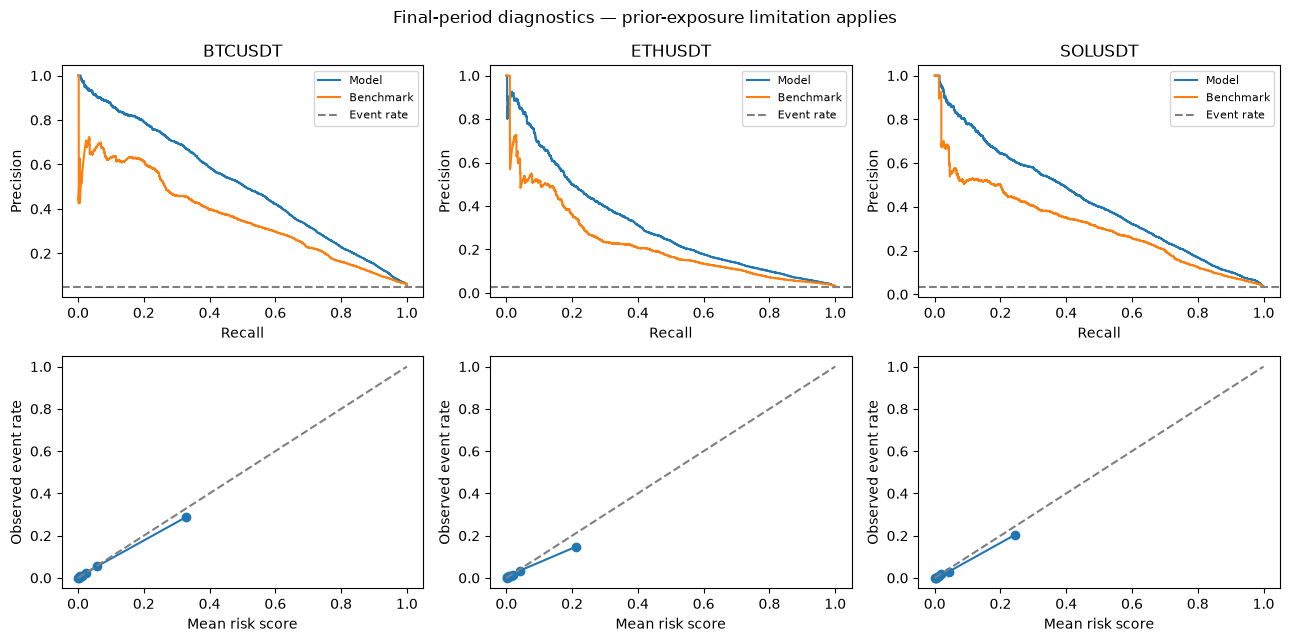

In [8]:
fig,axes = plt.subplots(2,3,figsize=(13,6.5))
for j,symbol in enumerate(SYMBOLS):
    mask = test.symbol.eq(symbol).to_numpy(); y = test.loc[mask,'y']; score = test_scores[mask]
    for label,values in [('Model',score),('Benchmark',test.loc[mask,'rv_60c_59r'].to_numpy())]:
        precision,recall,_ = precision_recall_curve(y,values)
        axes[0,j].plot(recall,precision,label=label)
    axes[0,j].axhline(y.mean(),ls='--',color='grey',label='Event rate')
    axes[0,j].set(title=symbol,xlabel='Recall',ylabel='Precision'); axes[0,j].legend(fontsize=8)
    observed,predicted = calibration_curve(y,score,n_bins=8,strategy='quantile')
    axes[1,j].plot(predicted,observed,'o-'); axes[1,j].plot([0,1],[0,1],'--',color='grey')
    axes[1,j].set(xlabel='Mean risk score',ylabel='Observed event rate')
fig.suptitle('Final-period diagnostics — prior-exposure limitation applies')
fig.tight_layout(); plt.show()


## 6. Verify saved inference without retraining
Load only trusted joblib files. The saved bundle includes the feature definitions and inference source from this notebook; no separate Python file is needed. A fresh Python process loads the saved model and scores 60 raw candles; both historical microseconds and REST milliseconds must match the offline prediction. Replay is explicit; live scoring requires approval and an agreed freshness limit.


In [9]:
example = train.iloc[0]
raw_request = assets[example.symbol].loc[lambda d:d.open_time.lt(example.decision_time)].tail(60).copy()
expected = float(selected_model.predict_proba(train.loc[[0],PREDICTORS])[0,1])
loaded = joblib.load(bundle_path)
actual = predict_candles(raw_request,loaded,mode='replay',as_of=example.decision_time)
np.testing.assert_allclose(actual['risk_score'],expected,rtol=1e-9,atol=1e-10)
for bad in [raw_request.iloc[:-1],raw_request.iloc[::-1],raw_request.assign(close=-1),
            raw_request.assign(open_time=raw_request.open_time.iloc[0])]:
    try: predict_candles(bad,loaded,mode='replay',as_of=example.decision_time)
    except ValueError: pass
    else: raise AssertionError('Malformed request accepted')
try: predict_candles(raw_request,loaded,mode='replay',as_of=example.decision_time-MINUTE)
except ValueError: pass
else: raise AssertionError('Incomplete candle accepted')
# Test the freshness mechanism using a test-only approval flag; never save this flag.
test_approved = {'model':loaded['model'],'metadata':{**loaded['metadata'],'approval_status':'approved'}}
try: predict_candles(raw_request,test_approved,mode='live',as_of=example.decision_time+MINUTE,max_age_seconds=30)
except ValueError: pass
else: raise AssertionError('Stale live input accepted')
try: predict_candles(raw_request,loaded,mode='live',as_of=example.decision_time,max_age_seconds=30)
except ValueError: pass
else: raise AssertionError('Unapproved live model accepted')

reload_code = """
import sys,json,types,joblib,pandas as pd,numpy as np
from pathlib import Path
folder=Path(sys.argv[1]);bundle=joblib.load(folder/'selected_model.joblib')
module=types.ModuleType('saved_inference');exec(bundle['metadata']['inference_source'],module.__dict__)
payload=json.loads(sys.stdin.read());frame=pd.DataFrame(payload['candles'])
for unit in ['ms','us']:
    converted=frame.copy();converted['open_time']=converted['open_time']*(1000 if unit=='us' else 1)
    result=module.predict_candles(converted,folder/'selected_model.joblib',mode='replay',as_of=payload['as_of'],unit=unit)
    np.testing.assert_allclose(result['risk_score'],payload['expected'],rtol=1e-9,atol=1e-10)
print('PASS: fresh-process raw-candle reload, historical us and REST ms predictions match.')
"""
payload_frame = raw_request.copy()
payload_frame['open_time'] = [int(x.value)//1_000_000 for x in raw_request.open_time]
payload = json.dumps({'candles':payload_frame.to_dict(orient='records'),
                      'as_of':example.decision_time.isoformat(),'expected':expected})
checked = subprocess.run([sys.executable,'-c',reload_code,str(model_folder)],input=payload,
                         capture_output=True,text=True,timeout=120)
if checked.returncode: raise RuntimeError(checked.stderr)
print(checked.stdout.strip())
assert hashlib.sha256(bundle_path.read_bytes()).hexdigest() == metadata['artifact_sha256']
assert all(hashlib.sha256((RAW/x['file']).read_bytes()).hexdigest()==x['sha256'] for x in manifest)
summary = {'selected_model':selected_name,'validation_macro_AP':float(comparison.iloc[0].macro_AP),
           'validation_benchmark_macro_AP':benchmark_ap,'required_macro_AP':required_ap,'gate_pass':gate_pass,
           'final_macro_AP':test_ap,'final_benchmark_macro_AP':test_base_ap,
           'final_relative_uplift':test_ap/test_base_ap-1,'approval_status':('candidate_pending_review' if gate_pass else 'failed_quality_gate'),
           'artifact':bundle_path.relative_to(ROOT).as_posix(),
           'checks':'UTC units, timing, gaps, purging, leakage perturbation, raw inference/reload and source hashes passed',
           'TBD':['Independent future confirmation','Probability calibration','Operational alert/freshness limits',
                  'Business assessment-time benefit','Model release review']}
(METRICS/'run_summary.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))


PASS: fresh-process raw-candle reload, historical us and REST ms predictions match.


{
  "selected_model": "Histogram Gradient Boosting",
  "validation_macro_AP": 0.5151451186975996,
  "validation_benchmark_macro_AP": 0.40865990903096994,
  "required_macro_AP": 0.4903918908371639,
  "gate_pass": true,
  "final_macro_AP": 0.41428027606090795,
  "final_benchmark_macro_AP": 0.3003454869366813,
  "final_relative_uplift": 0.37934576705740986,
  "approval_status": "candidate_pending_review",
  "artifact": "results/model/candidates/selected_model.joblib",
  "checks": "UTC units, timing, gaps, purging, leakage perturbation, raw inference/reload and source hashes passed",
  "TBD": [
    "Independent future confirmation",
    "Probability calibration",
    "Operational alert/freshness limits",
    "Business assessment-time benefit",
    "Model release review"
  ]
}
